Computer Vision Object Detector & Frame-by-Frame Segmenter Pipeline

Install OpenCV

In [1]:
!pip install opencv-python-headless

Import libraries

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

print("OpenCV version:", cv2.__version__)
print("Libraries imported successfully!")

OpenCV version: 5.0.0
Libraries imported successfully!


Upload video

In [3]:
from google.colab import files

uploaded = files.upload()

Saving 14737069_3840_2160_60fps.mp4 to 14737069_3840_2160_60fps.mp4


Get video filename

In [4]:
video_path = list(uploaded.keys())[0]

print("Uploaded video:", video_path)

Uploaded video: 14737069_3840_2160_60fps.mp4


Check video information

In [5]:
cap = cv2.VideoCapture(video_path)

if cap.isOpened():
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    print("FPS:", fps)
    print("Total Frames:", total_frames)
    print("Resolution:", width, "x", height)
else:
    print("Video could not be opened.")

cap.release()

FPS: 60.0
Total Frames: 1507
Resolution: 3840 x 2160


Extract first frame

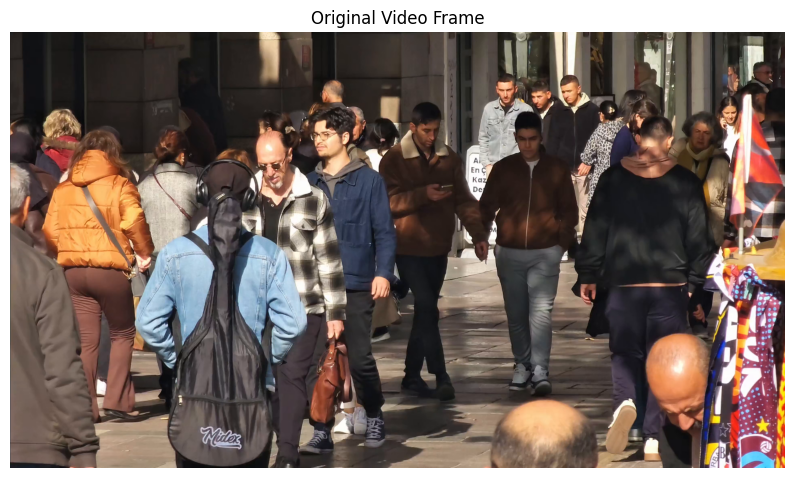

In [6]:
cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

cap.release()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(frame_rgb)
    plt.title("Original Video Frame")
    plt.axis("off")
    plt.show()
else:
    print("Could not read video frame.")

Gaussian Blur

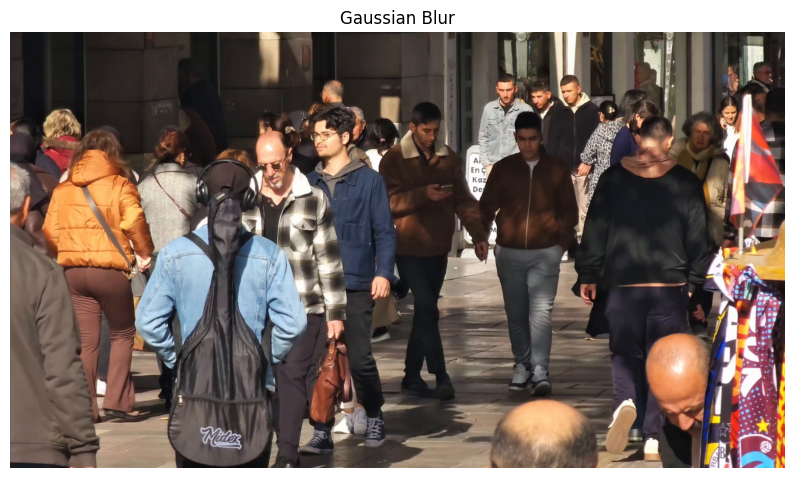

In [7]:
blurred = cv2.GaussianBlur(frame, (5, 5), 0)

blurred_rgb = cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(blurred_rgb)
plt.title("Gaussian Blur")
plt.axis("off")
plt.show()

Grayscale + Adaptive Thresholding

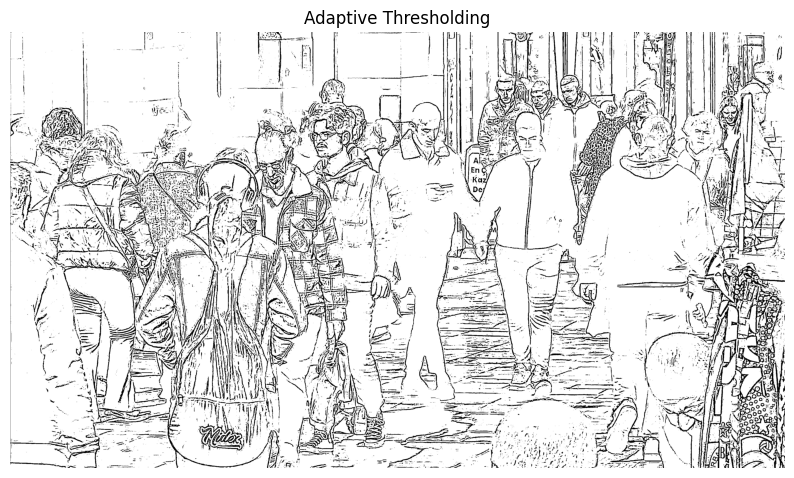

In [8]:
gray = cv2.cvtColor(blurred, cv2.COLOR_BGR2GRAY)

thresh = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

plt.figure(figsize=(10, 6))
plt.imshow(thresh, cmap="gray")
plt.title("Adaptive Thresholding")
plt.axis("off")
plt.show()

Find Contours

In [9]:
contours, hierarchy = cv2.findContours(
    thresh,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Total contours detected:", len(contours))

Total contours detected: 364


Filter Contours by Area

In [10]:
min_area = 500
max_area = 50000

filtered_contours = []

for contour in contours:
    area = cv2.contourArea(contour)

    if min_area < area < max_area:
        filtered_contours.append(contour)

print("Filtered objects:", len(filtered_contours))

Filtered objects: 27


Draw Detected Objects

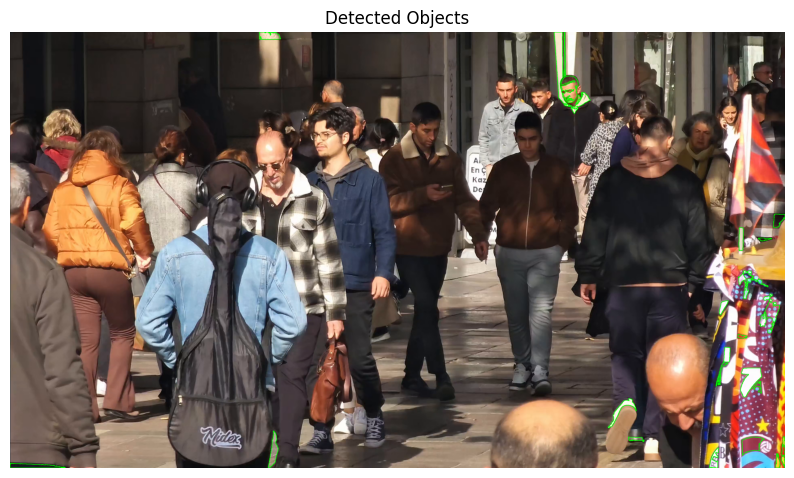

In [11]:
output_frame = frame.copy()

cv2.drawContours(
    output_frame,
    filtered_contours,
    -1,
    (0, 255, 0),
    2
)

output_rgb = cv2.cvtColor(output_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(output_rgb)
plt.title("Detected Objects")
plt.axis("off")
plt.show()

Process video frames

In [12]:
cap = cv2.VideoCapture(video_path)

frame_count = 0
total_objects = 0
processing_times = []

while True:
    ret, frame = cap.read()

    if not ret:
        break

    start_time = time.time()

    # Gaussian blur
    blurred = cv2.GaussianBlur(frame, (5, 5), 0)

    # Grayscale
    gray = cv2.cvtColor(blurred, cv2.COLOR_BGR2GRAY)

    # Adaptive threshold
    thresh = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        11, 2
    )

    # Find contours
    contours, _ = cv2.findContours(
        thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    # Filter by area
    filtered = [
        c for c in contours
        if 500 < cv2.contourArea(c) < 50000
    ]

    # Draw contours
    cv2.drawContours(frame, filtered, -1, (0, 255, 0), 2)

    # Add object count
    object_count = len(filtered)
    cv2.putText(
        frame,
        f"Objects: {object_count}",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 0, 255),
        2
    )

    processing_times.append(time.time() - start_time)
    total_objects += object_count
    frame_count += 1

    # Save sample processed frame
    if frame_count == 1:
        processed_frame = frame.copy()

cap.release()

print("Processed frames:", frame_count)
print("Total detected contour objects:", total_objects)

Processed frames: 1507
Total detected contour objects: 35674


Display processed frame

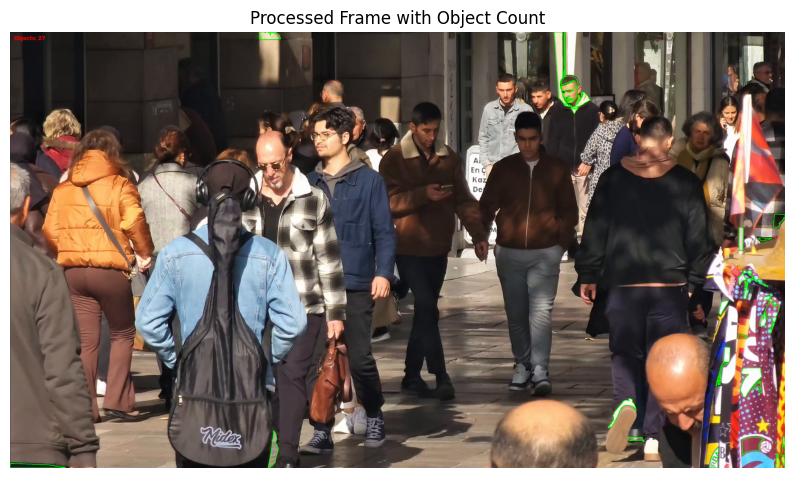

In [13]:
processed_rgb = cv2.cvtColor(processed_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(processed_rgb)
plt.title("Processed Frame with Object Count")
plt.axis("off")
plt.show()

Processing performance

In [14]:
if processing_times:
    avg_time = np.mean(processing_times)
    avg_fps = 1 / avg_time if avg_time > 0 else 0

    print("Average processing time per frame:", round(avg_time, 4), "seconds")
    print("Average processing FPS:", round(avg_fps, 2))

Average processing time per frame: 0.1649 seconds
Average processing FPS: 6.07


Create frame-by-frame log

In [15]:
import pandas as pd

log_data = {
    "Frame Number": list(range(1, frame_count + 1)),
    "Processing Time (seconds)": processing_times
}

df = pd.DataFrame(log_data)
df.head()

,Frame Number,Processing Time (seconds)
0,1,0.246384
1,2,0.154099
2,3,0.153630
3,4,0.154023
4,5,0.146209


Processed video save

In [16]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

if fps <= 0:
    fps = 25

output_path = "processed_output.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

video_frame_counts = []
frame_number = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    blurred = cv2.GaussianBlur(frame, (5, 5), 0)
    gray = cv2.cvtColor(blurred, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        11, 2
    )

    contours, _ = cv2.findContours(
        thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    filtered = [
        c for c in contours
        if 500 < cv2.contourArea(c) < 50000
    ]

    cv2.drawContours(frame, filtered, -1, (0, 255, 0), 2)

    count = len(filtered)
    video_frame_counts.append(count)
    frame_number += 1

    cv2.putText(
        frame,
        f"Frame: {frame_number} | Objects: {count}",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 255),
        2
    )

    out.write(frame)

cap.release()
out.release()

print("Processed video saved:", output_path)
print("Total frames processed:", frame_number)

Processed video saved: processed_output.mp4
Total frames processed: 1507


Download processed video

In [17]:
from google.colab import files

files.download("processed_output.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Graph: Object count per frame

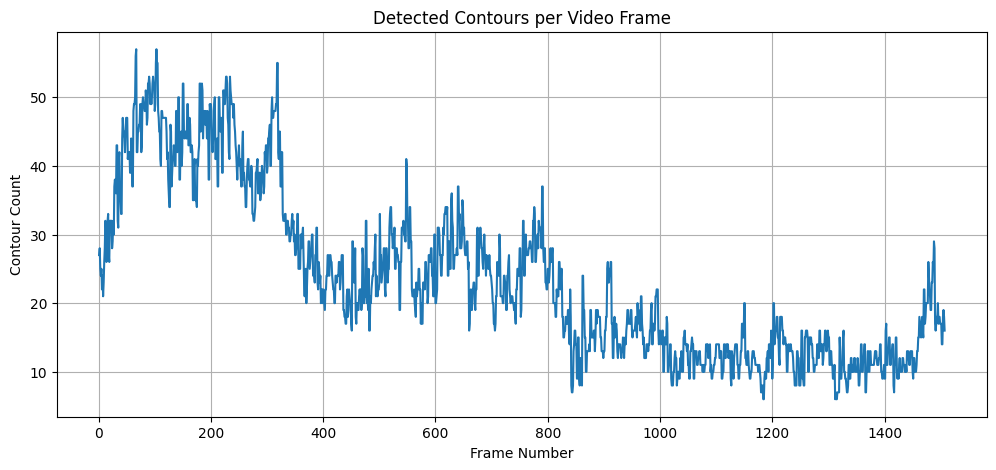

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, len(video_frame_counts) + 1),
    video_frame_counts
)

plt.title("Detected Contours per Video Frame")
plt.xlabel("Frame Number")
plt.ylabel("Contour Count")
plt.grid(True)
plt.show()

Graph: Processing time per frame

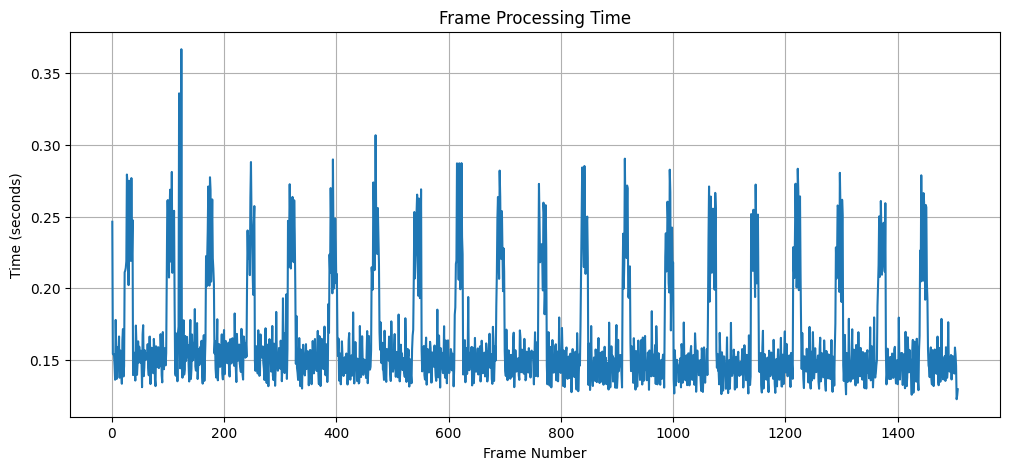

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, len(processing_times) + 1),
    processing_times
)

plt.title("Frame Processing Time")
plt.xlabel("Frame Number")
plt.ylabel("Time (seconds)")
plt.grid(True)
plt.show()

Save CSV logs

In [20]:
results_df = pd.DataFrame({
    "Frame Number": range(1, len(video_frame_counts) + 1),
    "Contour Count": video_frame_counts
})

results_df.to_csv("frame_detection_log.csv", index=False)

df.to_csv("processing_time_log.csv", index=False)

print("CSV logs saved successfully!")

CSV logs saved successfully!


Overall statistics

In [21]:
print("===== TASK 4 PERFORMANCE SUMMARY =====")

print("Video:", video_path)
print("Total Frames:", len(video_frame_counts))
print("Average Contours per Frame:",
      round(np.mean(video_frame_counts), 2))

print("Maximum Contours:",
      max(video_frame_counts))

print("Minimum Contours:",
      min(video_frame_counts))

print("Average Processing Time:",
      round(np.mean(processing_times), 4), "seconds")

print("Average Processing FPS:",
      round(1 / np.mean(processing_times), 2))

===== TASK 4 PERFORMANCE SUMMARY =====
Video: 14737069_3840_2160_60fps.mp4
Total Frames: 1507
Average Contours per Frame: 23.67
Maximum Contours: 57
Minimum Contours: 6
Average Processing Time: 0.1649 seconds
Average Processing FPS: 6.07


Save final summary

In [22]:
summary = pd.DataFrame({
    "Metric": [
        "Total Frames",
        "Average Contours per Frame",
        "Maximum Contours",
        "Minimum Contours",
        "Average Processing Time (seconds)",
        "Average Processing FPS"
    ],
    "Value": [
        len(video_frame_counts),
        round(np.mean(video_frame_counts), 2),
        max(video_frame_counts),
        min(video_frame_counts),
        round(np.mean(processing_times), 4),
        round(1 / np.mean(processing_times), 2)
    ]
})

summary.to_csv("performance_summary.csv", index=False)

summary

,Metric,Value
0,Total Frames,1507.0000
1,Average Contours per Frame,23.6700
2,Maximum Contours,57.0000
3,Minimum Contours,6.0000
4,Average Processing Time (seconds),0.1649
5,Average Processing FPS,6.0700
